In [6]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

INPUTDIR = Path.home() / Path('Desktop') / Path('PSY 46050 Project') / 'VIXSPX'
sys.path.insert(0, str(INPUTDIR))

from vixspx import HORIZONS, OUTPUT_DIR, load_data, add_features
from vixspx.prediction import _ols_hac

# Load and construct existing features
d = add_features(load_data(), HORIZONS)

print(d[["SPX", "VIX", "lnVIX", "f21"]].head())
print("Number of observations:", len(d))


                   SPX        VIX     lnVIX       f21
Date                                                 
1990-01-02  359.690002  17.240000  2.847232 -8.894171
1990-01-03  358.760010  18.190001  2.900872 -8.723439
1990-01-04  355.670013  19.219999  2.955951 -7.212668
1990-01-05  352.200012  20.110001  3.001217 -5.951615
1990-01-08  353.790009  20.260000  3.008649 -7.064171
Number of observations: 9285


In [ ]:
import pandas as pd
from IPython.display import display, Image

from vixspx import HORIZONS, OUTPUT_DIR, load_data, add_features
from vixspx.prediction import vix_momentum_interaction
from vixspx.plotting import plot_interaction

# load and construct existing features
d = add_features(load_data(), HORIZONS)
# run the interaction regression model and get the summary of stats
r = vix_momentum_interaction(d, h=21)
print(r.summary())

# For your reference, I ran the model, but findings suggest that past 21-day 
# S&P 500 momentum does not significantly moderate the relationship between VIX 
# and future 21-day S&P 500 returns. the overall interaction model explains 
# only 0.6% of the variance in future returns, suggesting limited explanatory power.

                            OLS Regression Results                            
Dep. Variable:                    f21   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                    0.7403
Date:                Fri, 13 Nov 2026   Prob (F-statistic):              0.528
Time:                        11:33:52   Log-Likelihood:                -27057.
No. Observations:                9243   AIC:                         5.412e+04
Df Residuals:                    9239   BIC:                         5.415e+04
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.6965      0.204      3.407      

/Users/3447783148qq.com/Desktop/PSY 46050 Project/VIXSPX/vixspx/plotting.py


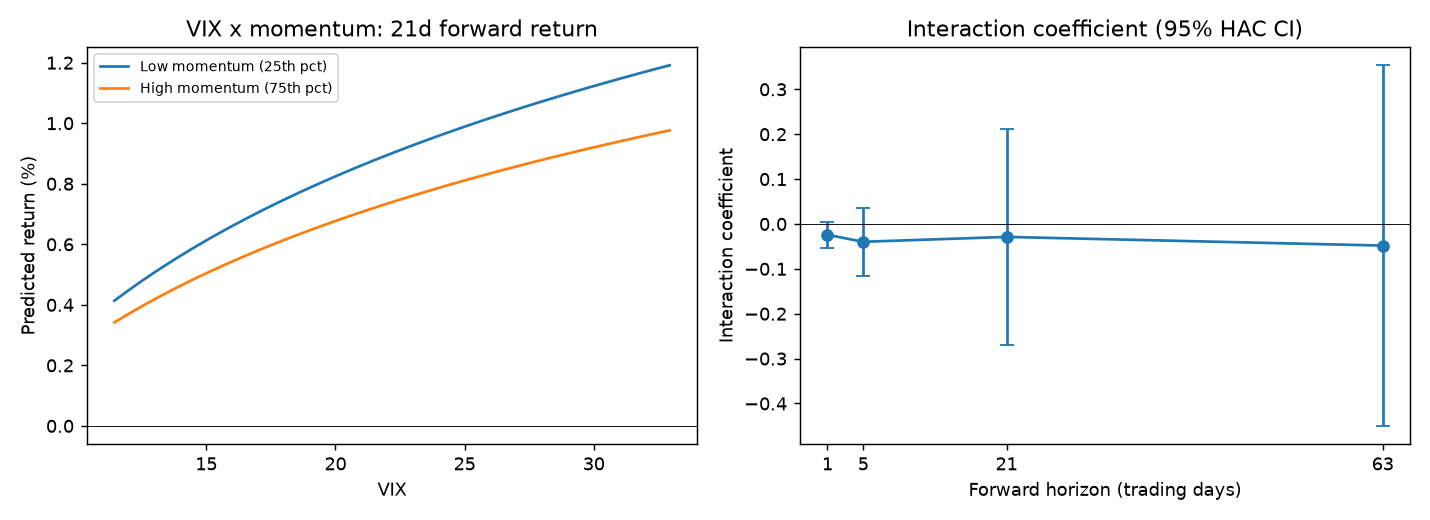

In [ ]:
import importlib
import vixspx.plotting as plotting

print(plotting.__file__) 
importlib.reload(plotting)

# Generate and display figure
path = plot_interaction(d, HORIZONS)
display(Image(filename=str(path)))

# Left panel: How does the relationship between VIX and future S&P 500 returns 
# differ depending on past S&P 500 momentum?

# Right panel: Is the interaction between VIX and momentum statistically 
# significant, and does its magnitude differ across forecasting horizons?

# For your reference, the the estimated interaction is very weak 
# and statistically nonsignificant (β = −0.0289, p = .815).
# You can see that the two lines do not cross each other.

# # +----------------------+----------------------------------------------------+-------------------------------------------------------------------+
# | Component            | What it represents                                 | Why it is included                                                |
# +----------------------+----------------------------------------------------+-------------------------------------------------------------------+
# | X-axis: VIX          | Current market-implied volatility                  | Main predictor                                                    |
# | Y-axis: Predicted    | Model-predicted 21-day S&P 500 log return          | Outcome                                                           |
# |   return (%)         |                                                    |                                                                   |
# | Low-momentum line    | Momentum at its 25th percentile                    | Represents relatively weak recent market performance              |
# | High-momentum line   | Momentum at its 75th percentile                    | Represents relatively strong recent market performance            |
# | Horizontal zero line | Predicted return = 0%                              | Distinguishes positive and negative predicted returns             |
# | Line slopes          | Estimated VIX–return relationships at fixed        | Shows whether the VIX association differs by momentum             |
# |                      |   momentum levels                                  |                                                                   |
# +----------------------+----------------------------------------------------+-------------------------------------------------------------------+
